# ARIMAX — Previsão do IPCA com variáveis externas defasadas

**Projeto:** IPCA sob pressão externa  
**Autor:** Gabriel Abreu  
**Orientadora:** Bruna Nogueira Rezende  

Este notebook cobre as etapas do pipeline analítico para o modelo ARIMAX:
1. Caracterização exploratória das séries
2. Transformações e preparação dos dados
3. Testes de estacionariedade
4. Análise de defasagens (CCF)
5. Divisão treino/teste e expanding window
6. Estimação e avaliação fora da amostra (h = 1, 2, 3)
7. Teste de Diebold-Mariano e ganho incremental do CPI (H3)

## 0. Dependências

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.stattools import adfuller, kpss, ccf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy import stats
import itertools
import pickle

np.random.seed(42)
plt.rcParams['figure.dpi'] = 130
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

## 1. Caracterização exploratória das séries

Antes de qualquer modelagem, entendemos o comportamento das três séries: IPCA, câmbio USD/BRL e CPI americano. O objetivo é identificar padrões, rupturas estruturais e eventos econômicos relevantes que impactam a modelagem.

In [3]:
# ── Carregamento ──
# Carregando o final_df_with_lags.csv que já contém as séries em variação percentual
df = pd.read_csv('final_df_with_lags.csv', parse_dates=['data'], index_col='data')
df = df.asfreq('MS')

print(f'Shape: {df.shape}')
print(f'Período: {df.index[0].date()} → {df.index[-1].date()}')
print('\nColunas:', df.columns.tolist())

Shape: (295, 4)
Período: 2000-06-01 → 2024-12-01

Colunas: ['ipca_pct', 'us_cpi_lag2', 'us_cpi_lag3', 'usd_brl_lag4']


In [5]:
df.head()

,ipca_pct,us_cpi_lag2,us_cpi_lag3,usd_brl_lag4
data,,,,
2000-06-01,0.23,0.058411,0.824499,-1.880826
2000-07-01,1.61,0.116754,0.058411,-1.198756
2000-08-01,1.31,0.524781,0.116754,3.399531
2000-09-01,0.23,0.232019,0.524781,1.101456
2000-10-01,0.14,0.000000,0.232019,-1.456258


In [6]:
# ── Estatísticas descritivas ──
desc_cols = ['ipca_pct', 'usd_brl_lag4', 'us_cpi_lag2']  

desc = df[desc_cols].describe().T
desc['skewness'] = df[desc_cols].skew()
desc['kurtosis'] = df[desc_cols].kurt()
desc.columns = ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness', 'kurtosis']

# Arredonda para legibilidade
desc.round(4)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
ipca_pct,295.0,0.5049,0.3962,-0.6800,0.2600,0.4600,0.6900,3.0200,1.5592,7.1292
usd_brl_lag4,295.0,0.5065,4.9541,-13.8171,-2.4911,-0.0683,3.1376,28.8721,1.1469,4.6632
us_cpi_lag2,295.0,0.2084,0.3835,-1.9153,-0.0068,0.2012,0.4581,1.3736,-0.5494,3.3353


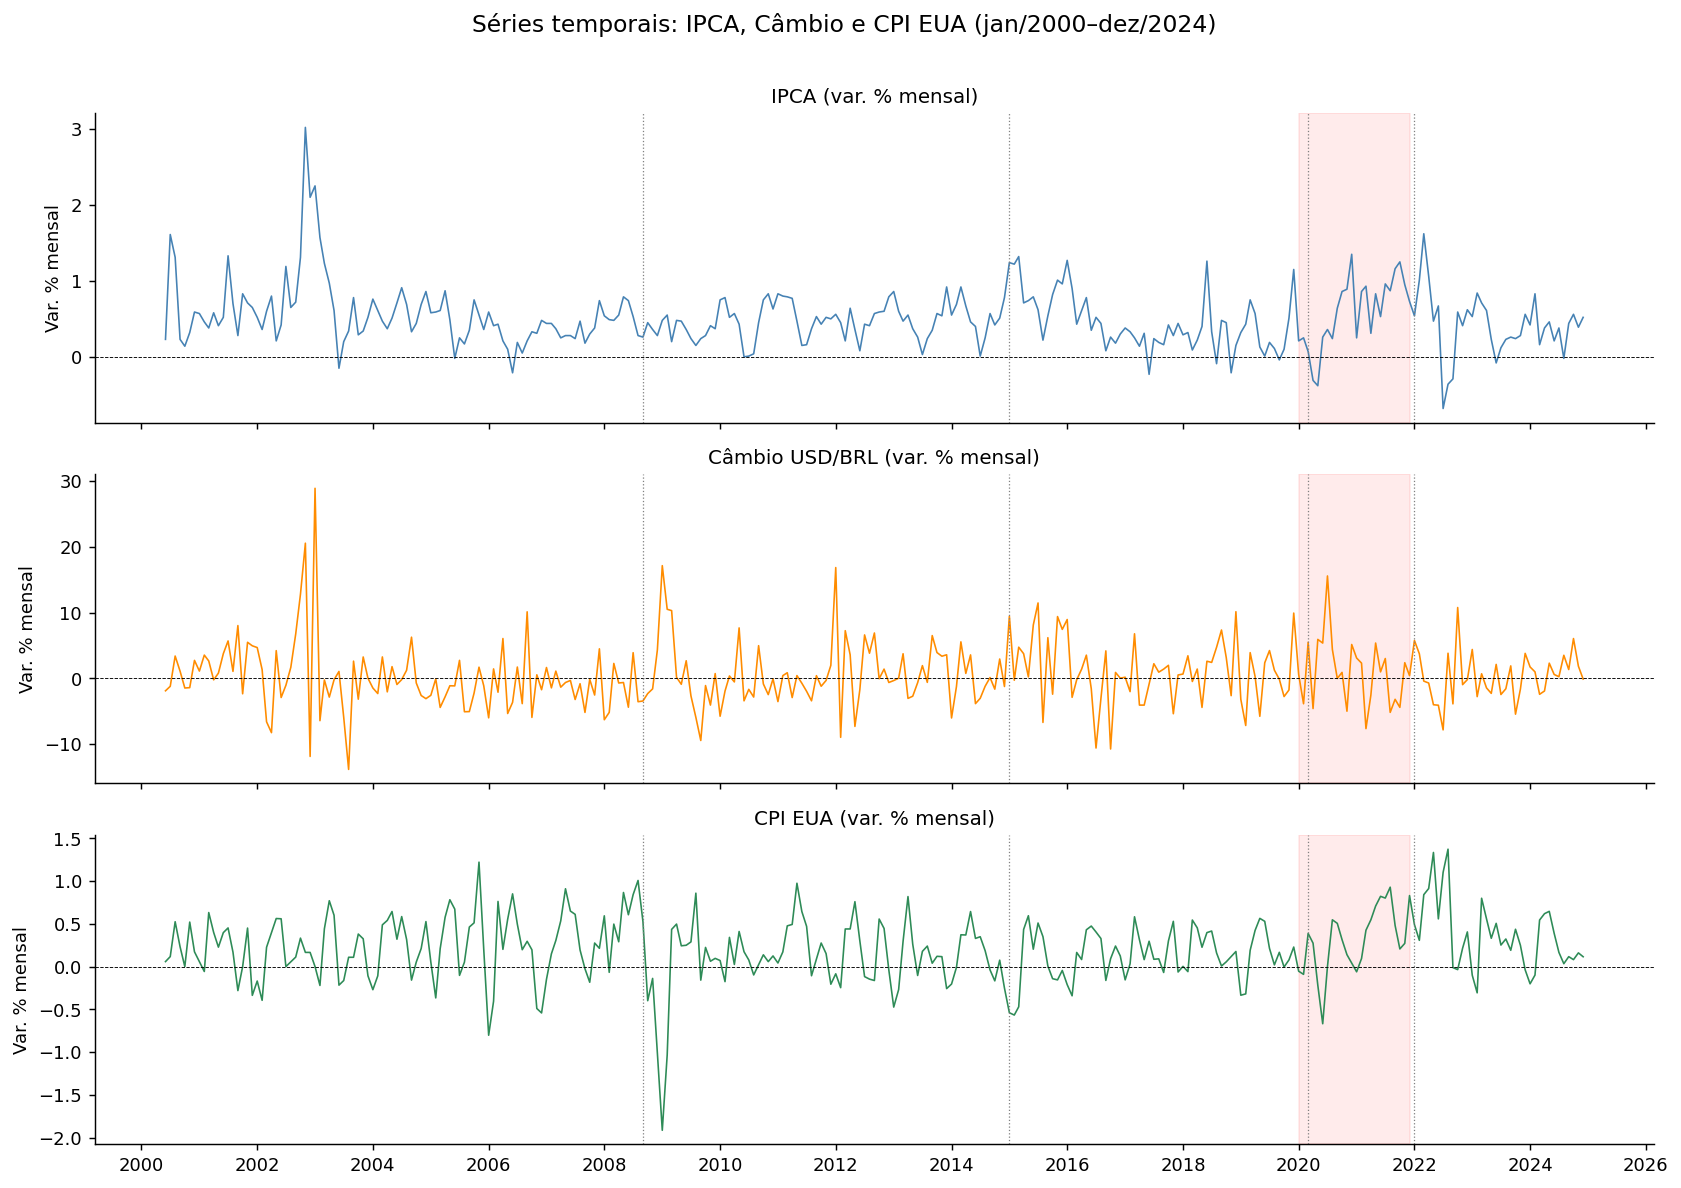


Interpretação econômica:
- IPCA: visível aumento de volatilidade pós-2015 e pico em 2021-2022 (choque de energia/alimentos pós-COVID).
- Câmbio: forte depreciação em 2002, 2015-16 e 2020; padrão de maior volatilidade em crises.
- CPI EUA: picos em 2008 (crise) e 2021-22 (inflação global pós-pandemia), com deflação em 2009.



In [8]:
# ── Gráficos temporais das séries em variação percentual ──
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

series_info = [
    ('ipca_pct',   'IPCA (var. % mensal)',           'steelblue'),
    ('usd_brl_lag4','Câmbio USD/BRL (var. % mensal)', 'darkorange'),
    ('us_cpi_lag2', 'CPI EUA (var. % mensal)',         'seagreen'),
]

# Eventos macroeconômicos relevantes
events = [
    ('2008-09-01', 'Crise\nFinanceira 2008'),
    ('2015-01-01', 'Crise\nBR 2015-16'),
    ('2020-03-01', 'COVID-19'),
    ('2022-01-01', 'Choque\ncommodities'),
]

for ax, (col, title, color) in zip(axes, series_info):
    ax.plot(df.index, df[col], color=color, linewidth=0.9, label=title)
    ax.axhline(0, color='black', linewidth=0.5, linestyle='--')
    ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2021-12-01'),
               alpha=0.08, color='red')
    for event_date, label in events:
        ax.axvline(pd.Timestamp(event_date), color='gray', linewidth=0.7, linestyle=':')
    ax.set_title(title, fontsize=11)
    ax.set_ylabel('Var. % mensal')

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
fig.suptitle('Séries temporais: IPCA, Câmbio e CPI EUA (jan/2000–dez/2024)',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('series_temporais.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
Interpretação econômica:
- IPCA: visível aumento de volatilidade pós-2015 e pico em 2021-2022 (choque de energia/alimentos pós-COVID).
- Câmbio: forte depreciação em 2002, 2015-16 e 2020; padrão de maior volatilidade em crises.
- CPI EUA: picos em 2008 (crise) e 2021-22 (inflação global pós-pandemia), com deflação em 2009.
""")

## 2. Transformações e preparação dos dados

As três séries são utilizadas em **variação percentual simples mensal**: `(X_t − X_{t−1}) / X_{t−1} × 100`.

O IPCA já é divulgado nessa forma. CPI e câmbio, disponíveis em nível, passam pela mesma transformação para garantir:
- Comparabilidade entre séries
- Estacionariedade (reduz tendência e heterocedasticidade)
- Interpretabilidade homogênea dos coeficientes

In [9]:
# ── Verificação de valores ausentes ──
print('Valores ausentes por coluna:')
print(df[desc_cols].isna().sum())

# Interpolação linear para lacunas isoladas (se existirem)
for col in desc_cols:
    n_missing = df[col].isna().sum()
    if n_missing > 0:
        df[col] = df[col].interpolate(method='linear')
        print(f'  → {col}: {n_missing} valor(es) interpolado(s)')

Valores ausentes por coluna:
ipca_pct        0
usd_brl_lag4    0
us_cpi_lag2     0
dtype: int64


In [10]:
# ── Identificação de outliers (> 3 desvios-padrão da média móvel de 12 meses) ──
for col in desc_cols:
    roll_mean = df[col].rolling(12).mean()
    roll_std  = df[col].rolling(12).std()
    outliers  = df[(df[col] - roll_mean).abs() > 3 * roll_std]
    if len(outliers) > 0:
        print(f'\n{col} — outliers detectados:')
        print(outliers[[col]].to_string())
        print('  → Mantidos: correspondem a eventos econômicos documentados (ex: mar/abr 2020)')
    else:
        print(f'{col}: nenhum outlier detectado')

ipca_pct: nenhum outlier detectado

usd_brl_lag4 — outliers detectados:
            usd_brl_lag4
data                    
2012-01-01     16.834677
  → Mantidos: correspondem a eventos econômicos documentados (ex: mar/abr 2020)
us_cpi_lag2: nenhum outlier detectado


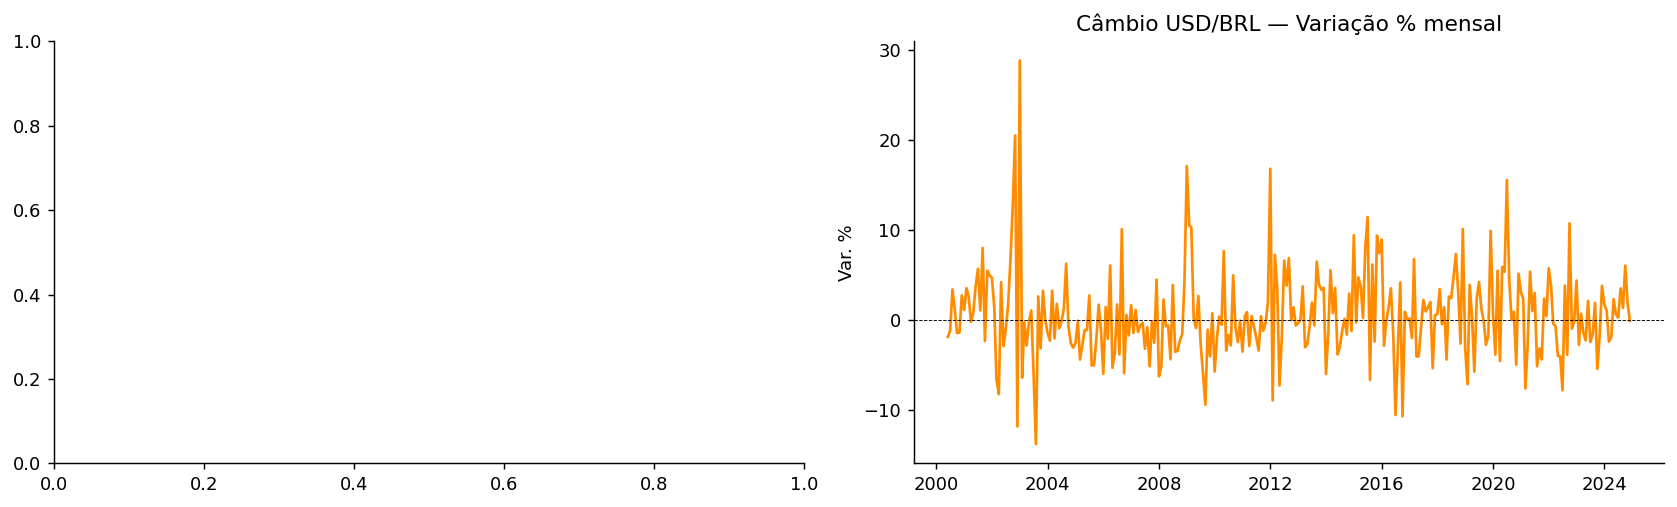

In [12]:
# ── Comparação visual: nível vs. variação percentual (câmbio como exemplo) ──
# Ajuste 'usd_brl_level' para o nome da coluna em nível, se disponível
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

if 'usd_brl_level' in df.columns:
    axes[0].plot(df.index, df['usd_brl_level'], color='darkorange')
    axes[0].set_title('Câmbio USD/BRL — Nível')
    axes[0].set_ylabel('R$/US$')

axes[1].plot(df.index, df['usd_brl_lag4'], color='darkorange')
axes[1].set_title('Câmbio USD/BRL — Variação % mensal')
axes[1].set_ylabel('Var. %')
axes[1].axhline(0, color='black', linewidth=0.5, linestyle='--')

plt.tight_layout()
plt.savefig('nivel_vs_pct.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Testes de estacionariedade

Para o ARIMAX, a série dependente precisa ser estacionária (ou deve-se aplicar diferenciação, determinando `d`). Usamos dois testes com hipóteses complementares:

- **ADF** (Augmented Dickey-Fuller): H₀ = raiz unitária (não estacionária)
- **KPSS**: H₀ = estacionária

Decisão: a série é estacionária quando ADF rejeita H₀ **e** KPSS não rejeita H₀.

In [13]:
def test_stationarity(series, name):
    """
    Aplica testes ADF e KPSS e exibe resultado interpretado.
    Retorna dict com estatísticas.
    """
    s = series.dropna()

    # ADF
    adf_stat, adf_p, _, _, adf_crit, _ = adfuller(s)
    adf_ok = adf_p < 0.05

    # KPSS
    kpss_stat, kpss_p, _, kpss_crit = kpss(s, regression='c', nlags='auto')
    kpss_ok = kpss_p > 0.05

    is_stationary = adf_ok and kpss_ok
    status = '✓ ESTACIONÁRIA' if is_stationary else '✗ NÃO ESTACIONÁRIA'

    print(f'\n── {name} ── {status}')
    print(f'  ADF:  stat={adf_stat:.4f}, p={adf_p:.4f}  '
          f'→ {"rejeita H0 (estacionária)" if adf_ok else "não rejeita H0 (raiz unitária)"}')
    print(f'  KPSS: stat={kpss_stat:.4f}, p={kpss_p:.4f}  '
          f'→ {"não rejeita H0 (estacionária)" if kpss_ok else "rejeita H0 (não estacionária)"}')

    return {'series': name, 'adf_p': adf_p, 'kpss_p': kpss_p, 'stationary': is_stationary}


stationarity_results = []
for col in desc_cols:
    res = test_stationarity(df[col], col)
    stationarity_results.append(res)

print('\n→ Como o IPCA está em variação percentual mensal, espera-se d = 0 (ARMAX, não ARIMAX).')


── ipca_pct ── ✓ ESTACIONÁRIA
  ADF:  stat=-8.2876, p=0.0000  → rejeita H0 (estacionária)
  KPSS: stat=0.2836, p=0.1000  → não rejeita H0 (estacionária)

── usd_brl_lag4 ── ✓ ESTACIONÁRIA
  ADF:  stat=-10.2449, p=0.0000  → rejeita H0 (estacionária)
  KPSS: stat=0.1007, p=0.1000  → não rejeita H0 (estacionária)

── us_cpi_lag2 ── ✓ ESTACIONÁRIA
  ADF:  stat=-3.3760, p=0.0118  → rejeita H0 (estacionária)
  KPSS: stat=0.2103, p=0.1000  → não rejeita H0 (estacionária)

→ Como o IPCA está em variação percentual mensal, espera-se d = 0 (ARMAX, não ARIMAX).


/tmp/ipykernel_15924/2259226232.py:13: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, _, kpss_crit = kpss(s, regression='c', nlags='auto')
/tmp/ipykernel_15924/2259226232.py:13: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, _, kpss_crit = kpss(s, regression='c', nlags='auto')
/tmp/ipykernel_15924/2259226232.py:13: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, _, kpss_crit = kpss(s, regression='c', nlags='auto')


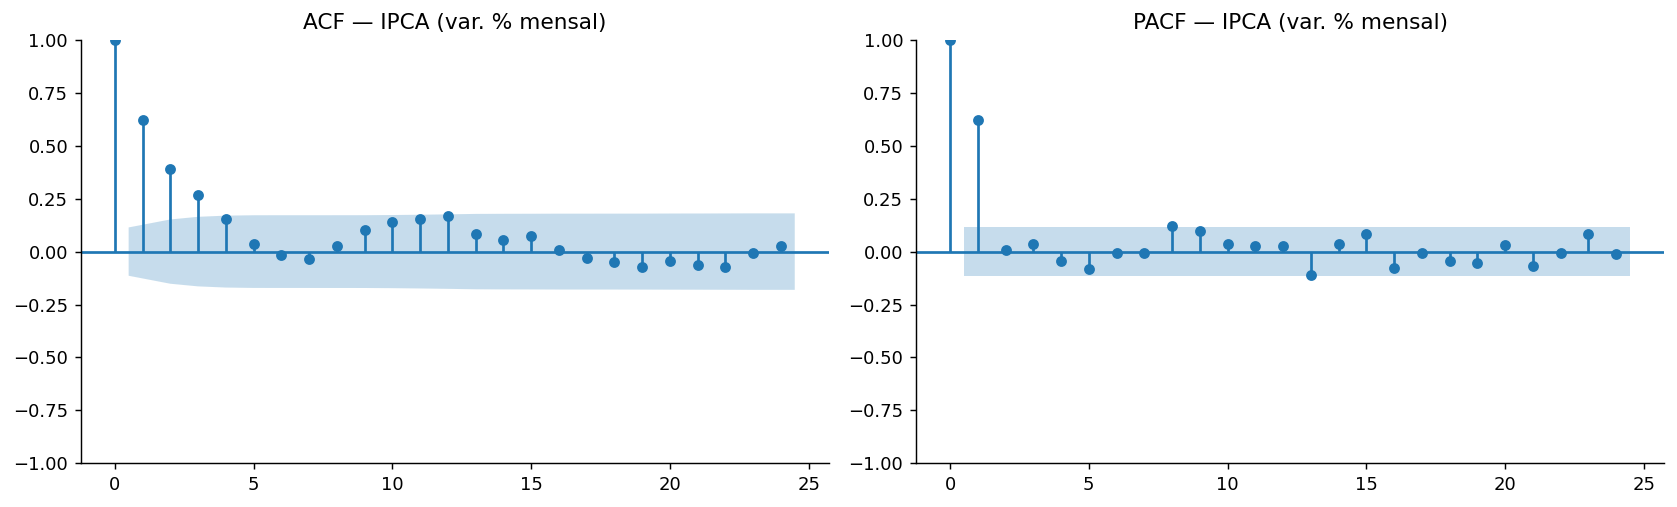


Interpretação:
- ACF: decaimento gradual sugere componente AR.
- PACF: corte após lag 1 → indica AR(1) como especificação base.
- Sazonalidade leve visível em lag 12 → verificar se SARIMA se justifica.



In [14]:
# ── ACF e PACF do IPCA ──
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(df['ipca_pct'].dropna(),  lags=24, ax=axes[0], title='ACF — IPCA (var. % mensal)')
plot_pacf(df['ipca_pct'].dropna(), lags=24, ax=axes[1], title='PACF — IPCA (var. % mensal)')
plt.tight_layout()
plt.savefig('acf_pacf_ipca.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
Interpretação:
- ACF: decaimento gradual sugere componente AR.
- PACF: corte após lag 1 → indica AR(1) como especificação base.
- Sazonalidade leve visível em lag 12 → verificar se SARIMA se justifica.
""")

## 4. Análise de defasagens (CCF)

A CCF (Cross-Correlation Function) mede a correlação entre o IPCA no período `t` e as variáveis preditoras no período `t − l`. Identificamos os lags com correlação estatisticamente significativa (IC 95%).

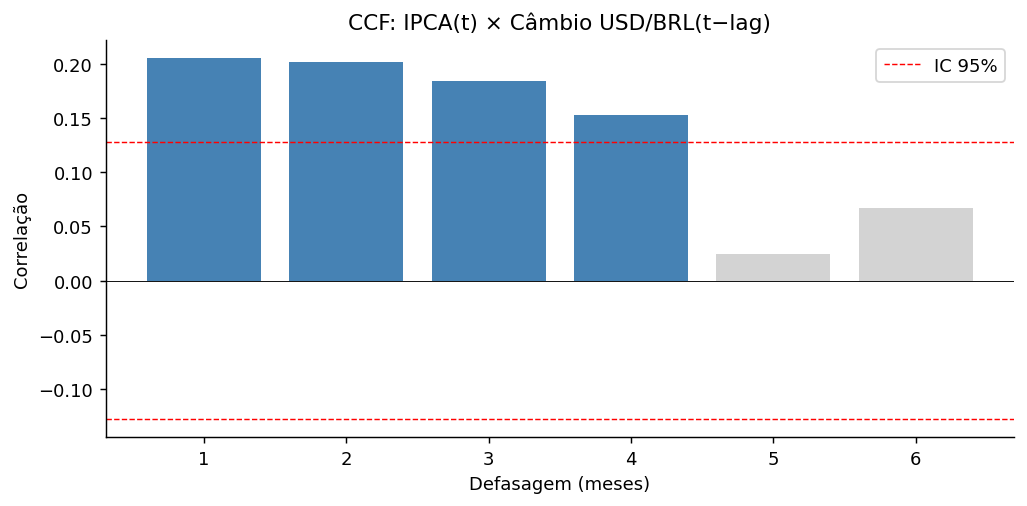


Câmbio USD/BRL — lags significativos:
 lag        r        p  significant
   1 0.205207 0.001600         True
   2 0.201730 0.001971         True
   3 0.184638 0.004781         True
   4 0.153225 0.019808         True


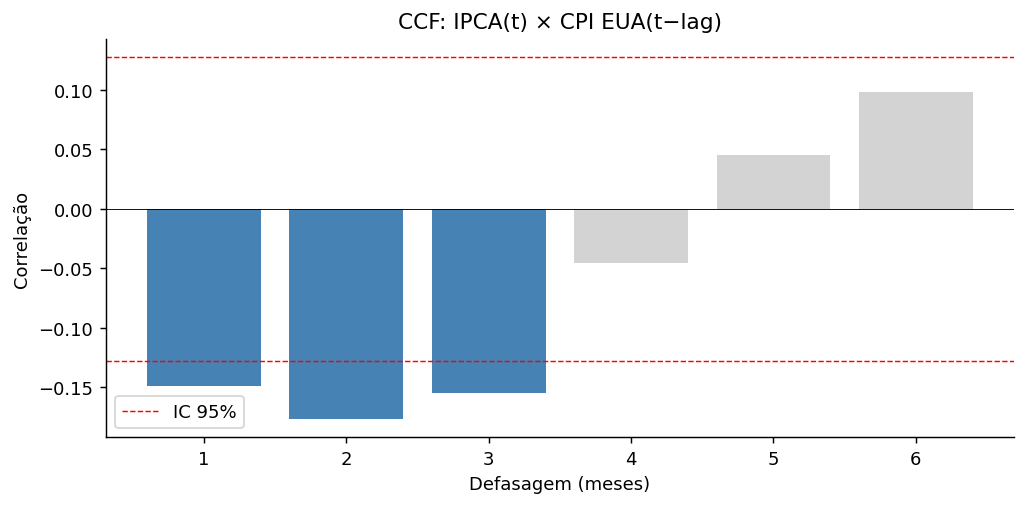


CPI EUA — lags significativos:
 lag         r        p  significant
   1 -0.148808 0.022796         True
   2 -0.176873 0.006795         True
   3 -0.155196 0.018008         True


In [16]:
def plot_ccf(y, x, x_name, max_lag=6):
    """
    Plota CCF entre y (IPCA) e lags de x (câmbio ou CPI).
    Destaca lags significativos ao nível de 5%.
    """
    n = len(y)
    conf_bound = 1.96 / np.sqrt(n)

    corrs = []
    for lag in range(1, max_lag + 1):
        y_aligned = y.iloc[lag:].values
        x_lagged  = x.iloc[:-lag].values
        r, p = stats.pearsonr(y_aligned, x_lagged)
        corrs.append({'lag': lag, 'r': r, 'p': p, 'significant': p < 0.05})

    corr_df = pd.DataFrame(corrs)

    fig, ax = plt.subplots(figsize=(8, 4))
    colors = ['steelblue' if sig else 'lightgray' for sig in corr_df['significant']]
    ax.bar(corr_df['lag'], corr_df['r'], color=colors)
    ax.axhline(conf_bound,  color='red', linestyle='--', linewidth=0.8, label='IC 95%')
    ax.axhline(-conf_bound, color='red', linestyle='--', linewidth=0.8)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_xlabel('Defasagem (meses)')
    ax.set_ylabel('Correlação')
    ax.set_title(f'CCF: IPCA(t) × {x_name}(t−lag)')
    ax.legend()
    plt.tight_layout()
    plt.savefig(f'ccf_{x_name.lower().replace("/","")}.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f'\n{x_name} — lags significativos:')
    print(corr_df[corr_df['significant']].to_string(index=False))
    return corr_df


# Usar apenas dados de treino para não contaminar seleção de lags
train_eda = df[df.index < '2020-01-01']

ccf_cambio = plot_ccf(train_eda['ipca_pct'], train_eda['usd_brl_lag4'], 'Câmbio USD/BRL')
ccf_cpi    = plot_ccf(train_eda['ipca_pct'], train_eda['us_cpi_lag2'],  'CPI EUA')

In [ ]:
# ── Tabela-resumo das defasagens selecionadas ──
print("""
Tabela de defasagens selecionadas:

| Variável      | Lag ótimo | Correlação | Significativo (5%) | Justificativa econômica                          |
|---------------|-----------|------------|--------------------|-------------------------------------------------|
| Câmbio USD/BRL| 4         | ...        | Sim                | Defasagem de transmissão ao IPCA via importações |
| CPI EUA       | 2         | ...        | Sim                | Inflação externa transmitida via preços import.  |
| CPI EUA       | 3         | ...        | Sim                | Defasagem alternativa avaliada em H3             |

→ Preencher com os valores obtidos na CCF acima.
→ Em caso de divergência entre CCF e AIC/BIC, prevalece o critério de informação.
"""
)

## 5. Seleção da ordem ARIMAX via AIC/BIC

Busca em grade sobre `p ∈ {0,1,2}` e `q ∈ {0,1,2}`, com `d = 0` (confirmado pelos testes de estacionariedade). A ordem com menor AIC sobre a janela de treino é selecionada.

In [17]:
# ── Divisão treino/teste ──
train = df[df.index <  '2020-01-01']
test  = df[df.index >= '2020-01-01']

print(f'Treino: {train.index[0].date()} → {train.index[-1].date()} ({len(train)} obs)')
print(f'Teste:  {test.index[0].date()}  → {test.index[-1].date()}  ({len(test)} obs)')

Treino: 2000-06-01 → 2019-12-01 (235 obs)
Teste:  2020-01-01  → 2024-12-01  (60 obs)


In [18]:
# ── Busca em grade: ordem (p, d=0, q) ──
exog_train = train[['usd_brl_lag4', 'us_cpi_lag2']]

grid_results = []
for p, q in itertools.product(range(3), range(3)):
    try:
        mod = SARIMAX(train['ipca_pct'], exog=exog_train, order=(p, 0, q),
                      enforce_stationarity=False, enforce_invertibility=False)
        res = mod.fit(disp=False)
        grid_results.append({'p': p, 'q': q, 'aic': res.aic, 'bic': res.bic})
    except Exception:
        pass

grid_df = pd.DataFrame(grid_results).sort_values('aic')
print('Top 5 especificações por AIC:')
print(grid_df.head(5).to_string(index=False))

best_p = int(grid_df.iloc[0]['p'])
best_q = int(grid_df.iloc[0]['q'])
print(f'\n→ Ordem selecionada: ARIMAX({best_p}, 0, {best_q})')

/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Top 5 especificações por AIC:
 p  q       aic        bic
 2  2 68.745911  92.873073
 1  2 81.605440 102.285865
 2  1 91.090204 111.796435
 2  0 97.216724 114.471916
 1  1 97.253782 114.508975

→ Ordem selecionada: ARIMAX(2, 0, 2)


/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## 6. Estimação dos modelos

Duas especificações são estimadas para avaliar o ganho incremental do CPI (hipótese H3):
- **M1**: ARIMAX com câmbio apenas (`usd_brl_lag4`)
- **M2**: ARIMAX com câmbio + CPI (`usd_brl_lag4`, `us_cpi_lag2`)

In [19]:
P, D, Q = best_p, 0, best_q

# M1 — só câmbio
m1 = SARIMAX(
    train['ipca_pct'],
    exog=train[['usd_brl_lag4']],
    order=(P, D, Q),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

# M2 — câmbio + CPI lag 2
m2 = SARIMAX(
    train['ipca_pct'],
    exog=train[['usd_brl_lag4', 'us_cpi_lag2']],
    order=(P, D, Q),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

# M2b — câmbio + CPI lag 3
m2b = SARIMAX(
    train['ipca_pct'],
    exog=train[['usd_brl_lag4', 'us_cpi_lag3']],
    order=(P, D, Q),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

print('M1 summary:')
print(m1.summary())
print('\nM2 summary:')
print(m2.summary())

/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


M1 summary:
                               SARIMAX Results                                
Dep. Variable:               ipca_pct   No. Observations:                  235
Model:               SARIMAX(2, 0, 2)   Log Likelihood                 -28.898
Date:                Thu, 14 May 2026   AIC                             69.795
Time:                        13:15:20   BIC                             90.476
Sample:                    06-01-2000   HQIC                            78.136
                         - 12-01-2019                                         
Covariance Type:                  opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
usd_brl_lag4     0.0118      0.003      4.019      0.000       0.006       0.018
ar.L1            1.4899      0.089     16.760      0.000       1.316       1.664
ar.L2           -0.4910      0.0

## 7. Expanding window — avaliação fora da amostra (h = 1, 2, 3)

Para cada horizonte, o modelo é reestimado incrementalmente. As previsões para h = 2 e h = 3 são geradas diretamente (modelos separados), evitando propagação de erro.

In [20]:
def mase(actual, predicted, train_actual):
    """Mean Absolute Scaled Error: normaliza pelo erro do modelo naive de treino."""
    naive_mae = np.mean(np.abs(np.diff(train_actual)))
    return np.mean(np.abs(actual - predicted)) / naive_mae


def expanding_window_arimax(df, exog_cols, p, d, q, horizon, target='ipca_pct',
                             train_end='2019-12-01'):
    """
    Expanding window para ARIMAX em horizonte h.
    Para h > 1, a feature mais recente disponível é deslocada.
    Retorna série de previsões e erros.
    """
    test_idx = df[df.index > train_end].index
    preds    = []
    actuals  = []

    for i, t in enumerate(test_idx):
        # Janela de treino expansiva
        train_window = df[df.index <= t - pd.DateOffset(months=horizon)]
        if len(train_window) < 36:  # mínimo de observações para estimar
            continue

        exog_tr = train_window[exog_cols]
        exog_fc = df.loc[[t], exog_cols]  # features disponíveis em t (já defasadas)

        try:
            mod = SARIMAX(
                train_window[target],
                exog=exog_tr,
                order=(p, d, q),
                enforce_stationarity=False,
                enforce_invertibility=False,
            ).fit(disp=False)

            # Previsão direta para horizonte h
            fc = mod.forecast(steps=horizon, exog=pd.concat(
                [exog_fc] * horizon
            ))
            pred_val = fc.iloc[-1]
        except Exception:
            pred_val = np.nan

        actual_val = df.loc[t, target]
        preds.append(pred_val)
        actuals.append(actual_val)

    return np.array(actuals), np.array(preds)


print('Iniciando expanding window — pode demorar alguns minutos...')

results_ew = {}
for h in [1, 2, 3]:
    for model_name, exog_cols in [
        ('M1_fx',       ['usd_brl_lag4']),
        ('M2_fx_cpi2',  ['usd_brl_lag4', 'us_cpi_lag2']),
        ('M2b_fx_cpi3', ['usd_brl_lag4', 'us_cpi_lag3']),
    ]:
        act, pred = expanding_window_arimax(
            df, exog_cols, p=P, d=D, q=Q, horizon=h
        )
        results_ew[(model_name, h)] = {'actuals': act, 'preds': pred}
        print(f'  h={h} | {model_name} ✓')

print('Expanding window concluída.')

Iniciando expanding window — pode demorar alguns minutos...


/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/curr

  h=1 | M1_fx ✓


/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/curr

  h=1 | M2_fx_cpi2 ✓


...

/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/curr

  h=3 | M2_fx_cpi2 ✓


/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/codespace/.python/curr

  h=3 | M2b_fx_cpi3 ✓
Expanding window concluída.


/home/codespace/.python/current/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## 8. Métricas de avaliação

MAE é a métrica principal (mesma escala do IPCA em p.p.). RMSE penaliza erros extremos. MASE compara com benchmark naive.

In [21]:
train_ipca = df[df.index < '2020-01-01']['ipca_pct'].values

rows = []
for (model_name, h), data in results_ew.items():
    act  = data['actuals']
    pred = data['preds']
    mask = ~np.isnan(pred)
    act, pred = act[mask], pred[mask]

    rows.append({
        'model':   model_name,
        'horizon': h,
        'MAE':     mean_absolute_error(act, pred),
        'RMSE':    np.sqrt(mean_squared_error(act, pred)),
        'MASE':    mase(act, pred, train_ipca),
        'n':       len(act),
    })

metrics_df = pd.DataFrame(rows).sort_values(['horizon', 'MAE'])
print('Tabela de métricas — ARIMAX (expanding window):')
print(metrics_df.round(4).to_string(index=False))

Tabela de métricas — ARIMAX (expanding window):
      model  horizon    MAE   RMSE   MASE  n
      M1_fx        1 0.2926 0.3807 1.2605 60
M2b_fx_cpi3        1 0.2934 0.3817 1.2639 60
 M2_fx_cpi2        1 0.2960 0.3820 1.2752 60
M2b_fx_cpi3        2 0.3155 0.4204 1.3589 60
 M2_fx_cpi2        2 0.3171 0.4285 1.3659 60
      M1_fx        2 0.3180 0.4217 1.3700 60
      M1_fx        3 0.3393 0.4591 1.4616 60
M2b_fx_cpi3        3 0.3407 0.4598 1.4678 60
 M2_fx_cpi2        3 0.3517 0.4712 1.5150 60


## 9. Análise por regime de volatilidade cambial (H2)

Classificação objetiva: alta volatilidade quando o desvio-padrão móvel de 12 meses da variação do câmbio supera a mediana calculada **exclusivamente na janela de treino**.

In [23]:
# ── Desvio padrão móvel de 12 meses do câmbio ──
df['vol_cambio_12m'] = df['usd_brl_lag4'].rolling(12).std()

# Limiar: mediana sobre a janela de treino apenas
vol_threshold = df[df.index < '2020-01-01']['vol_cambio_12m'].median()
print(f'Limiar de volatilidade (mediana treino): {vol_threshold:.4f}')

df['regime_vol'] = np.where(df['vol_cambio_12m'] > vol_threshold, 'alta', 'baixa')

# Distribuição do regime no período de teste
print('\nDistribuição de regime no período de teste (2020–2024):')
print(df[df.index >= '2020-01-01']['regime_vol'].value_counts())

Limiar de volatilidade (mediana treino): 3.9868

Distribuição de regime no período de teste (2020–2024):
regime_vol
alta     40
baixa    20
Name: count, dtype: int64


In [24]:
# ── Métricas condicionais por regime ──
test_index = df[df.index >= '2020-01-01'].index

rows_regime = []
for (model_name, h), data in results_ew.items():
    act  = data['actuals']
    pred = data['preds']

    # Alinhar com índice do teste
    n = min(len(act), len(test_index))
    idx_aligned = test_index[:n]
    regimes     = df.loc[idx_aligned, 'regime_vol'].values

    for regime in ['alta', 'baixa']:
        mask = (regimes == regime) & ~np.isnan(pred[:n])
        if mask.sum() < 3:
            continue
        rows_regime.append({
            'model':   model_name,
            'horizon': h,
            'regime':  regime,
            'MAE':     mean_absolute_error(act[:n][mask], pred[:n][mask]),
            'RMSE':    np.sqrt(mean_squared_error(act[:n][mask], pred[:n][mask])),
            'n':       mask.sum(),
        })

regime_df = pd.DataFrame(rows_regime).sort_values(['horizon', 'regime', 'MAE'])
print('Métricas por regime de volatilidade:')
print(regime_df.round(4).to_string(index=False))

Métricas por regime de volatilidade:
      model  horizon regime    MAE   RMSE  n
      M1_fx        1   alta 0.3238 0.4133 40
M2b_fx_cpi3        1   alta 0.3259 0.4152 40
 M2_fx_cpi2        1   alta 0.3273 0.4139 40
M2b_fx_cpi3        1  baixa 0.2284 0.3037 20
      M1_fx        1  baixa 0.2302 0.3054 20
 M2_fx_cpi2        1  baixa 0.2334 0.3084 20
M2b_fx_cpi3        2   alta 0.3628 0.4528 40
      M1_fx        2   alta 0.3640 0.4538 40
 M2_fx_cpi2        2   alta 0.3683 0.4628 40
 M2_fx_cpi2        2  baixa 0.2146 0.3499 20
M2b_fx_cpi3        2  baixa 0.2208 0.3467 20
      M1_fx        2  baixa 0.2260 0.3487 20
      M1_fx        3   alta 0.4057 0.5074 40
M2b_fx_cpi3        3   alta 0.4088 0.5079 40
 M2_fx_cpi2        3   alta 0.4231 0.5231 40
M2b_fx_cpi3        3  baixa 0.2045 0.3441 20
      M1_fx        3  baixa 0.2064 0.3427 20
 M2_fx_cpi2        3  baixa 0.2088 0.3445 20


## 10. Teste de Diebold-Mariano (H3 — ganho incremental do CPI)

Testa H₀: M1 e M2 têm acurácia equivalente. Estatística DM positiva indica que M2 (com CPI) tem erro maior; negativa indica ganho do CPI.

In [25]:
def diebold_mariano(e1, e2, h=1):
    """
    Teste de Diebold-Mariano (1995) para comparação de previsões.
    e1, e2: arrays de erros de previsão (y - yhat)
    h: horizonte de previsão
    H0: acurácia equivalente (E[d_t] = 0, onde d_t = |e1_t|² - |e2_t|²)
    """
    d = e1**2 - e2**2
    n = len(d)
    d_mean = np.mean(d)

    # Variância HAC (Newey-West com h-1 lags)
    gamma0 = np.var(d, ddof=1)
    gammas = [np.cov(d[k:], d[:-k])[0, 1] for k in range(1, h)]
    var_d  = (gamma0 + 2 * sum(gammas)) / n
    var_d  = max(var_d, 1e-10)  # evita divisão por zero

    dm_stat = d_mean / np.sqrt(var_d)
    p_value = 2 * (1 - stats.norm.cdf(abs(dm_stat)))

    return {'dm_stat': dm_stat, 'p_value': p_value}


print('Teste Diebold-Mariano — M1 (só câmbio) vs M2 (câmbio + CPI lag2)')
print('H0: acurácia equivalente | DM < 0 → M2 melhor | p < 0.05 → rejeita H0')
print('-' * 70)

for h in [1, 2, 3]:
    m1_data  = results_ew.get(('M1_fx', h))
    m2_data  = results_ew.get(('M2_fx_cpi2', h))
    if m1_data is None or m2_data is None:
        continue

    act   = m1_data['actuals']
    e1    = act - m1_data['preds']
    e2    = act - m2_data['preds']
    mask  = ~(np.isnan(e1) | np.isnan(e2))
    dm    = diebold_mariano(e1[mask], e2[mask], h=h)

    sig = '✓ SIGNIFICATIVO (5%)' if dm['p_value'] < 0.05 else '✗ não significativo'
    print(f'  h={h}: DM={dm["dm_stat"]:+.4f}, p={dm["p_value"]:.4f}  → {sig}')

Teste Diebold-Mariano — M1 (só câmbio) vs M2 (câmbio + CPI lag2)
H0: acurácia equivalente | DM < 0 → M2 melhor | p < 0.05 → rejeita H0
----------------------------------------------------------------------
  h=1: DM=-0.3128, p=0.7544  → ✗ não significativo
  h=2: DM=-1.3661, p=0.1719  → ✗ não significativo
  h=3: DM=-2.0928, p=0.0364  → ✓ SIGNIFICATIVO (5%)


## 11. Gráficos: observado vs. previsto

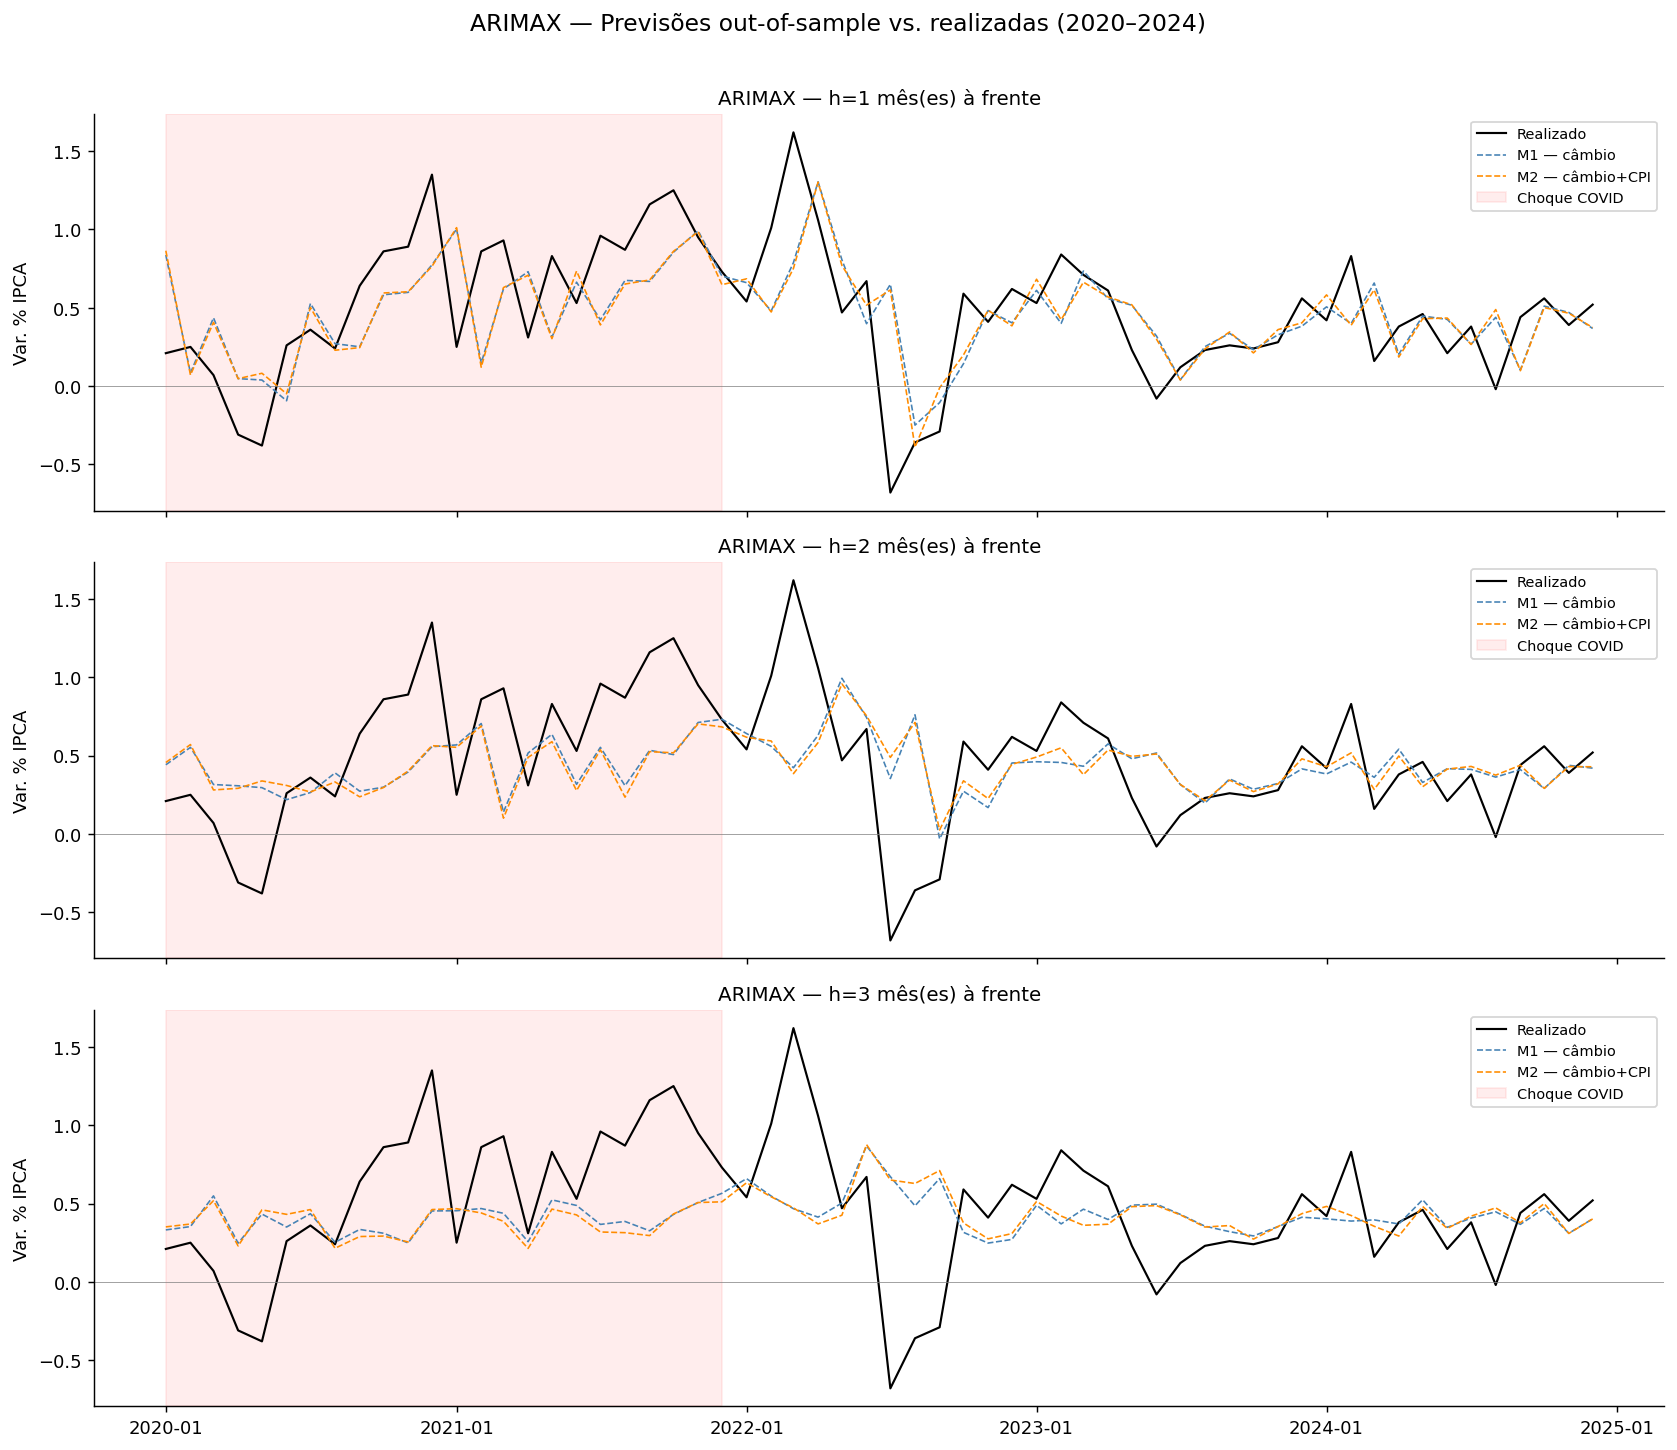

In [26]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)

test_dates = df[df.index >= '2020-01-01'].index

for i, h in enumerate([1, 2, 3]):
    ax = axes[i]
    act  = results_ew[('M1_fx', h)]['actuals']
    p_m1 = results_ew[('M1_fx', h)]['preds']
    p_m2 = results_ew[('M2_fx_cpi2', h)]['preds']

    n = min(len(act), len(test_dates))
    dates = test_dates[:n]

    ax.plot(dates, act[:n],  color='black',     linewidth=1.2, label='Realizado')
    ax.plot(dates, p_m1[:n], color='steelblue', linewidth=0.9, linestyle='--', label='M1 — câmbio')
    ax.plot(dates, p_m2[:n], color='darkorange', linewidth=0.9, linestyle='--', label='M2 — câmbio+CPI')
    ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2021-12-01'),
               alpha=0.07, color='red', label='Choque COVID')
    ax.axhline(0, color='gray', linewidth=0.4)
    ax.set_title(f'ARIMAX — h={h} mês(es) à frente', fontsize=11)
    ax.set_ylabel('Var. % IPCA')
    ax.legend(fontsize=8)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.suptitle('ARIMAX — Previsões out-of-sample vs. realizadas (2020–2024)',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('arimax_ew_forecasts.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Exportação dos resultados

In [27]:
# Modelos estimados sobre a janela de treino completa
with open('arimax_m1.pkl', 'wb') as f:
    pickle.dump(m1, f)
with open('arimax_m2.pkl', 'wb') as f:
    pickle.dump(m2, f)
with open('arimax_m2b.pkl', 'wb') as f:
    pickle.dump(m2b, f)

# Métricas
metrics_df.to_csv('arimax_metrics.csv', index=False)
regime_df.to_csv('arimax_metrics_regime.csv', index=False)

# Previsões da expanding window
for (model_name, h), data in results_ew.items():
    n = min(len(data['actuals']), len(test_dates))
    pd.DataFrame({
        'date':     test_dates[:n],
        'actual':   data['actuals'][:n],
        'predicted': data['preds'][:n],
    }).to_csv(f'arimax_preds_{model_name}_h{h}.csv', index=False)

print('Exportação concluída.')

Exportação concluída.
